# Punto 8 (0.7) — Corrección de balance de color

Se ha identificado una imagen con problemas de balance de color (`imagen_desbalanceada.tiff`). Se le ha solicitado que (1) identifique qué tipo de desbalance tiene y (2) aplique las transformaciones necesarias para obtener una imagen corregida con un SSIM de más de 0.99 con respecto a `imagen_objetivo.tiff`.

Ayuda: utilice el espacio CMY.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from skimage.metrics import structural_similarity as ssim

import sys
sys.path.append("..")
from colorspaces import rgb_to_cmy, cmy_to_rgb


## Imágenes dadas

(1024, 1024, 3) (1024, 1024, 3)


SSIM inicial: 0.9336


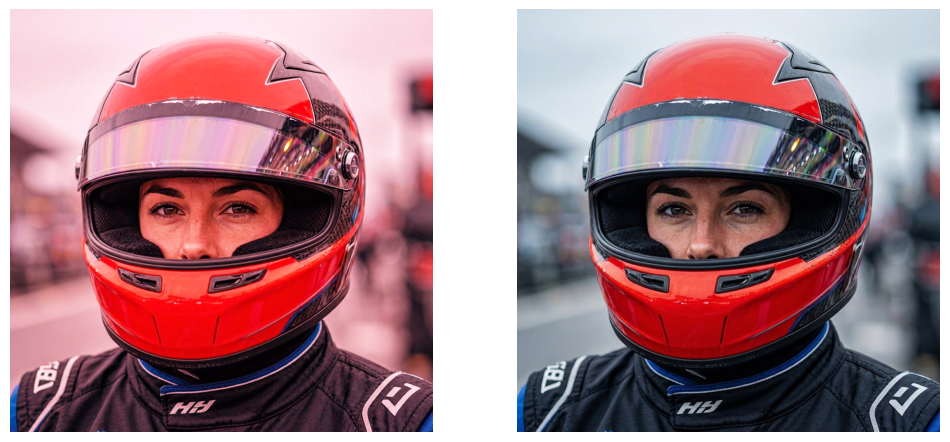

In [2]:
desbalanceada = np.array(Image.open("../images/imagen_desbalanceada.tiff").convert("RGB"))
objetivo = np.array(Image.open("../images/imagen_objetivo.tiff").convert("RGB"))
print(desbalanceada.shape, objetivo.shape)

print(f"SSIM inicial: {ssim(desbalanceada, objetivo, channel_axis=2, data_range=255):.4f}")

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(desbalanceada)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(objetivo)
plt.axis("off")
plt.savefig("../results/punto8_dadas.png", bbox_inches="tight", pad_inches=0)

Image.fromarray(objetivo).save("../results/punto8_objetivo.png")


## Tipo de desbalance

Tipo de desbalance: exceso de rojo, es decir, déficit del componente Cian. Magenta y Amarillo son idénticos en ambas imágenes; solo el Cian cambió, y lo hizo siguiendo una transformación gamma con γ = 2.5 aplicada a ese componente.

In [3]:
cmy_des = rgb_to_cmy(desbalanceada)
cmy_obj = rgb_to_cmy(objetivo)

print("Media CMY desbalanceada:", (cmy_des.reshape(-1, 3).mean(axis=0) * 255).round(1))
print("Media CMY objetivo:     ", (cmy_obj.reshape(-1, 3).mean(axis=0) * 255).round(1))
print("Magenta y Amarillo idénticos:", np.array_equal(cmy_des[..., 1:], cmy_obj[..., 1:]))

c_des = cmy_des[..., 0]
c_obj = cmy_obj[..., 0]
mascara = (c_obj > 0.1) & (c_obj < 0.9) & (c_des > 0)
gamma_estimado = np.median(np.log(c_des[mascara]) / np.log(c_obj[mascara]))
print(f"γ aplicado al Cian (estimado): {gamma_estimado:.2f}")


Media CMY desbalanceada: [ 81.7 148.4 139.4]
Media CMY objetivo:      [130.2 148.4 139.4]
Magenta y Amarillo idénticos: True
γ aplicado al Cian (estimado): 2.50


## Corrección en CMY

Se invierte el gamma sobre el Cian: γ = 1 / 2.5 = 0.4.

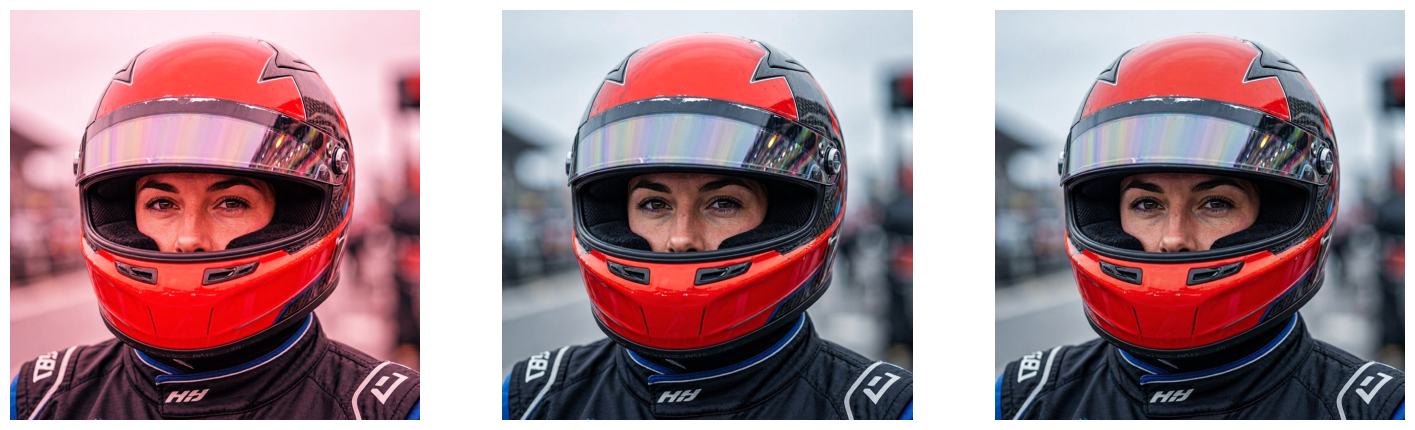

In [4]:
gamma_desbalance = round(float(gamma_estimado), 1)
gamma_correccion = 1 / gamma_desbalance

cian = np.round(cmy_des[..., 0] * 255).astype(np.uint8)
cian_corregido = np.zeros_like(cian)
cv2.intensity_transform.gammaCorrection(cian, cian_corregido, gamma_correccion)

cmy_corregida = cmy_des.copy()
cmy_corregida[..., 0] = cian_corregido / 255.0
corregida = cmy_to_rgb(cmy_corregida)

Image.fromarray(corregida).save("../results/punto8_corregida.png")

plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(desbalanceada)
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(corregida)
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(objetivo)
plt.axis("off")
plt.savefig("../results/punto8_comparacion.png", bbox_inches="tight", pad_inches=0)


## SSIM contra la imagen objetivo

SSIM obtenido: **0.9940** (pasa de 0.9336 a 0.9940, mayor a 0.99).

In [5]:
ssim_corregida = ssim(corregida, objetivo, channel_axis=2, data_range=255)
print(f"SSIM corregida vs objetivo: {ssim_corregida:.4f}")
assert ssim_corregida > 0.99


SSIM corregida vs objetivo: 0.9940
